# Irish Wind Curtailment: 2009–2012

## Research objectives

This project investigates the temporal and spatial characteristics of potential
wind energy curtailment in the Irish electricity system over the period
2009–2012.

The modelling framework extends the approach of McKenna et al. (2015), combining
historical wind reanalysis data, a turbine power curve, regional installed wind
capacity and electricity demand to estimate potential wind generation and
curtailment.

The main objectives are:

1. Estimate hourly wind generation from meteorological reanalysis data.
2. Aggregate wind generation across four Irish regions and nationally.
3. Estimate potential wind curtailment under operational system constraints.
4. Investigate interannual, seasonal and regional differences in curtailment.
5. Examine the sensitivity of curtailment to system operating assumptions.

## Scope

The analysis covers 2009–2012, using CFSR reanalysis data for 2009–2010 and
CFSv2 data for 2011–2012.

The baseline scenario assumes:

- Installed wind capacity: 5,061 MW
- System Non-Synchronous Penetration (SNSP) limit: 60%
- Interconnector exports: 0 MW
- Demand multiplier: 1.00

The notebook presents and analyses results already generated by the Python
modelling pipeline. It does not rerun the underlying data-processing or
curtailment simulations.

## Computational workflow and provenance

The results presented here were generated using the following scripts,
executed in sequence:

| Stage | Script | Purpose |
|---|---|---|
| 1 | `process_demand.py` | Process the ESBM electricity demand dataset |
| 2 | `build_wind_capacity_factors.py` | Calculate hourly wind capacity factors for 2009–2012 |
| 3 | `prepare_curtailment_inputs.py` | Combine wind generation and demand into model inputs |
| 4 | `run_curtailment.py` | Run and test the single-year curtailment model |
| 5 | `run_curtailment_all_years.py` | Run the baseline curtailment scenario for all four years |

The notebook uses the CSV outputs produced by these scripts. This separation
allows the numerical modelling and the subsequent analysis to remain distinct.

The main result files are:

- `curtailment_summary_2009_2012.csv`
- `curtailment_results_2009_2012.csv`
- `curtailment_results_2009.csv`
- `curtailment_results_2010.csv`
- `curtailment_results_2011.csv`
- `curtailment_results_2012.csv`

In [1]:
# Import Path for platform-independent file and directory handling.
from pathlib import Path

# Import pandas for reading and analysing CSV data.
import pandas as pd

# Import numpy for numerical operations.
import numpy as np

# Import matplotlib for producing figures.
import matplotlib.pyplot as plt

# Display figures directly inside the notebook.
%matplotlib inline

In [2]:
# Define the Git repository root.
# The notebook is assumed to be stored inside the "notebooks" directory.
PROJECT_ROOT = Path.home() / "Projects" / "Wind-curtailment"

# Define the external directory containing the model inputs and outputs.
DATA_ROOT = Path.home() / "Projects" / "Wind_curtailment_data"

# Define the directory containing the final curtailment CSV outputs.
RESULTS_DIR = DATA_ROOT / "curtailment_results"

# Define a directory inside the repository for figures intended for publication.
FIGURES_DIR = PROJECT_ROOT / "docs" / "figures"

# Create the figures directory if it does not already exist.
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Check that the expected directories exist before continuing.
assert PROJECT_ROOT.exists(), f"Project directory not found: {PROJECT_ROOT}"
assert RESULTS_DIR.exists(), f"Results directory not found: {RESULTS_DIR}"

# Display the locations being used.
print(f"Project repository: {PROJECT_ROOT}")
print(f"Model results:      {RESULTS_DIR}")
print(f"Figures directory:  {FIGURES_DIR}")

Project repository: /home/giulio/Projects/Wind-curtailment
Model results:      /home/giulio/Projects/Wind_curtailment_data/curtailment_results
Figures directory:  /home/giulio/Projects/Wind-curtailment/docs/figures


In [3]:
# Define the path to the summary CSV generated by the batch model run.
summary_file = RESULTS_DIR / "curtailment_summary_2009_2012.csv"

# Read the existing results without rerunning the model.
summary = pd.read_csv(summary_file)

# Display the complete summary table.
display(summary)

# Check the structure of the loaded dataset.
print("\nAvailable columns:")
print(summary.columns.tolist())

,year,hours,available_wind_energy_mwh,curtailed_energy_mwh,delivered_wind_energy_mwh,curtailment_percentage,mean_demand_mw,mean_wind_mw,hours_with_curtailment
0,2009,8759.0,1.313897e+07,1.872654e+06,1.126632e+07,14.252670,4633.022569,1500.054070,1639.0
1,2010,8759.0,9.545765e+06,1.148579e+06,8.397186e+06,12.032341,4473.332076,1089.823576,1024.0
2,2011,8760.0,1.200215e+07,1.812379e+06,1.018977e+07,15.100453,4644.607899,1370.108385,1631.0
3,2012,8784.0,1.061805e+07,1.126942e+06,9.491109e+06,10.613457,4703.264526,1208.794496,1093.0
4,ALL,35062.0,4.530494e+07,5.960555e+06,3.934438e+07,13.156523,4613.621617,1292.137887,5387.0



Available columns:
['year', 'hours', 'available_wind_energy_mwh', 'curtailed_energy_mwh', 'delivered_wind_energy_mwh', 'curtailment_percentage', 'mean_demand_mw', 'mean_wind_mw', 'hours_with_curtailment']


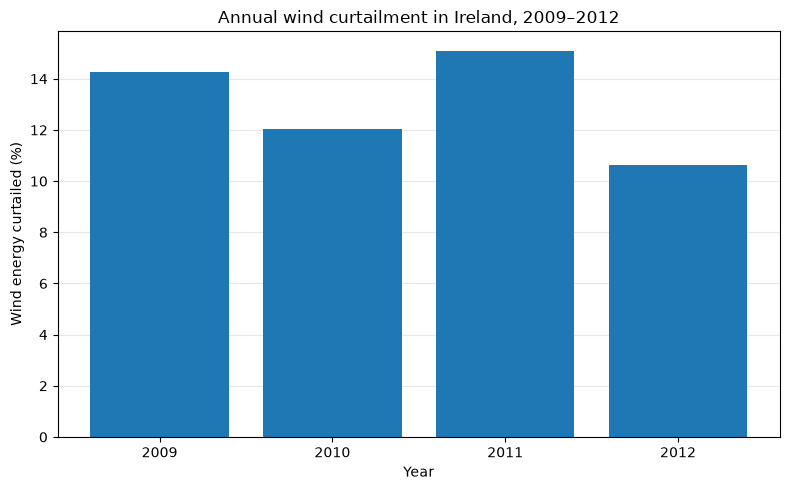

In [4]:
# Exclude the combined four-year row so that the plot contains annual values only.
annual_results = summary[summary["year"].astype(str) != "ALL"].copy()

# Convert the year column to integers for chronological ordering.
annual_results["year"] = annual_results["year"].astype(int)

# Sort the results by year.
annual_results = annual_results.sort_values("year")

# Extract the annual curtailment percentages.
curtailment = annual_results["curtailment_percentage"].astype(float)

# Convert fractions to percentages if the CSV stores values between zero and one.
if curtailment.max() <= 1:
    curtailment = curtailment * 100

# Create the figure and axes.
fig, ax = plt.subplots(figsize=(8, 5))

# Plot annual curtailment.
ax.bar(annual_results["year"].astype(str), curtailment)

# Add axis labels and a descriptive title.
ax.set_xlabel("Year")
ax.set_ylabel("Wind energy curtailed (%)")
ax.set_title("Annual wind curtailment in Ireland, 2009–2012")

# Add a light horizontal grid to help compare values.
ax.grid(axis="y", alpha=0.3)

# Keep the grid behind the bars.
ax.set_axisbelow(True)

# Improve the figure layout.
fig.tight_layout()

# Save a high-resolution copy in the repository.
fig.savefig(
    FIGURES_DIR / "annual_wind_curtailment.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the figure in the notebook.
plt.show()

## 1. Annual wind energy balance

The first analysis compares the potential wind energy available in each year
with the energy curtailed by system constraints and the energy remaining
available for delivery.

The distinction is important: a high curtailment percentage does not
necessarily imply the largest absolute energy loss. The amount of wind
resource available also varies between years.

The following figure presents the annual energy balance for the baseline
scenario.

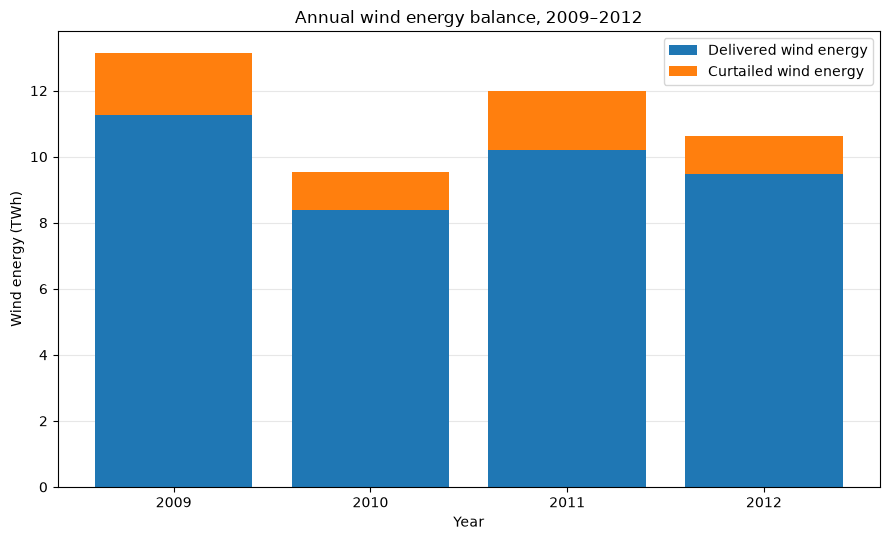

In [5]:
# Extract the annual energy quantities from the summary dataset.
available = annual_results["available_wind_energy_mwh"] / 1e6
curtailed = annual_results["curtailed_energy_mwh"] / 1e6
delivered = annual_results["delivered_wind_energy_mwh"] / 1e6

# Create a figure for the annual energy balance.
fig, ax = plt.subplots(figsize=(9, 5.5))

# Plot delivered wind energy as the lower part of each stacked bar.
ax.bar(
    annual_results["year"].astype(str),
    delivered,
    label="Delivered wind energy"
)

# Plot curtailed energy on top of delivered energy.
ax.bar(
    annual_results["year"].astype(str),
    curtailed,
    bottom=delivered,
    label="Curtailed wind energy"
)

# Add axis labels and title.
ax.set_xlabel("Year")
ax.set_ylabel("Wind energy (TWh)")
ax.set_title("Annual wind energy balance, 2009–2012")

# Add a legend and horizontal grid.
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

# Adjust spacing and save the figure.
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "annual_wind_energy_balance.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the figure.
plt.show()

## 2. Interannual variability in wind curtailment

The curtailment percentage provides a measure of the proportion of potential
wind energy that cannot be delivered to the electricity system.

It is calculated as:

\[
\text{Curtailment (\%)} =
100 \times
\frac{\text{Curtailed wind energy}}
{\text{Available wind energy}}
\]

The results indicate substantial interannual variability, with curtailment
ranging from approximately 10.6% to 15.1% under the baseline assumptions.

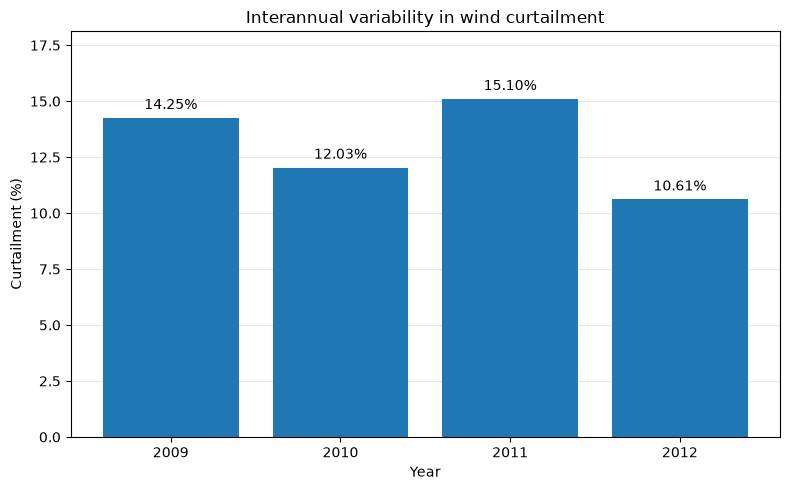

In [6]:
# Create a figure showing annual curtailment percentages.
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the annual values.
bars = ax.bar(
    annual_results["year"].astype(str),
    curtailment
)

# Add the percentage value above each bar.
for bar, value in zip(bars, curtailment):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.25,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

# Add labels and title.
ax.set_xlabel("Year")
ax.set_ylabel("Curtailment (%)")
ax.set_title("Interannual variability in wind curtailment")

# Set a little extra space above the tallest bar.
ax.set_ylim(0, max(curtailment) * 1.2)

# Add a horizontal grid.
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

# Save and display the figure.
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "annual_curtailment_percentage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 3. Frequency of curtailment events

The number of hours with non-zero curtailment provides a complementary
measure of system behaviour.

This metric does not distinguish between small and large curtailment events.
It is therefore interpreted alongside the energy-based curtailment
percentage.

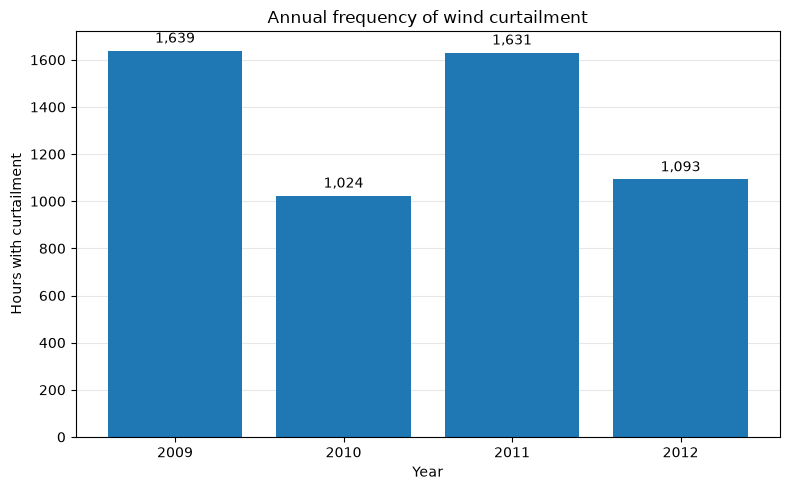

In [7]:
# Extract the annual number of hours with non-zero curtailment.
curtailment_hours = annual_results["hours_with_curtailment"]

# Create the figure.
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the annual number of curtailment hours.
bars = ax.bar(
    annual_results["year"].astype(str),
    curtailment_hours
)

# Annotate each bar with its numerical value.
for bar, value in zip(bars, curtailment_hours):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 20,
        f"{int(value):,}",
        ha="center",
        va="bottom"
    )

# Add labels and title.
ax.set_xlabel("Year")
ax.set_ylabel("Hours with curtailment")
ax.set_title("Annual frequency of wind curtailment")

# Add grid and improve layout.
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()

# Save and display the figure.
fig.savefig(
    FIGURES_DIR / "annual_curtailment_hours.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 4. Overall results for 2009–2012

Across the four-year period, the model estimates the total potential wind
energy, curtailed energy and delivered wind energy.

The combined curtailment percentage is calculated using the ratio of total
curtailed energy to total available wind energy. It is therefore an
energy-weighted measure, rather than the arithmetic average of the four
annual percentages.

,Metric,Value,Unit
0,Available wind energy,45.304939,TWh
1,Curtailed wind energy,5.960555,TWh
2,Delivered wind energy,39.344384,TWh
3,Curtailment percentage,13.156523,%


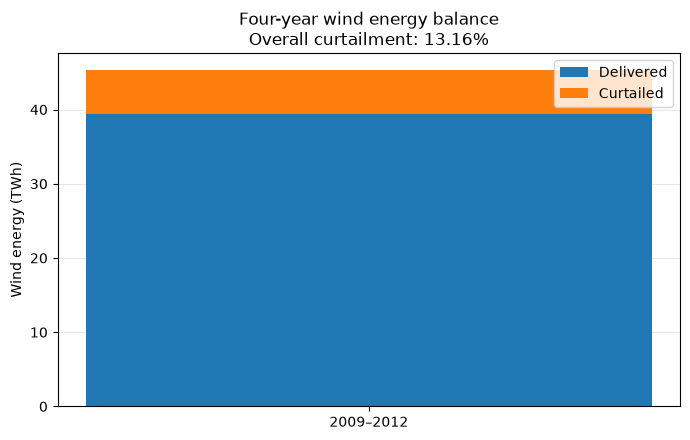

In [8]:
# Calculate the combined energy quantities across all four years.
total_available = annual_results["available_wind_energy_mwh"].sum()
total_curtailed = annual_results["curtailed_energy_mwh"].sum()
total_delivered = annual_results["delivered_wind_energy_mwh"].sum()

# Calculate the energy-weighted curtailment percentage.
overall_curtailment = 100 * total_curtailed / total_available

# Create a table of the combined results.
overall_results = pd.DataFrame({
    "Metric": [
        "Available wind energy",
        "Curtailed wind energy",
        "Delivered wind energy",
        "Curtailment percentage"
    ],
    "Value": [
        total_available / 1e6,
        total_curtailed / 1e6,
        total_delivered / 1e6,
        overall_curtailment
    ],
    "Unit": ["TWh", "TWh", "TWh", "%"]
})

# Display the results.
display(overall_results)

# Create a figure showing the combined energy balance.
fig, ax = plt.subplots(figsize=(7, 4.5))

# Plot the two components of the available wind energy.
ax.bar(
    ["2009–2012"],
    [total_delivered / 1e6],
    label="Delivered"
)

ax.bar(
    ["2009–2012"],
    [total_curtailed / 1e6],
    bottom=[total_delivered / 1e6],
    label="Curtailed"
)

# Add labels and title.
ax.set_ylabel("Wind energy (TWh)")
ax.set_title(
    f"Four-year wind energy balance\n"
    f"Overall curtailment: {overall_curtailment:.2f}%"
)

# Add legend and grid.
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

# Save and display.
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "four_year_energy_balance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 5. Hourly analysis of wind curtailment

Annual statistics conceal much of the temporal structure of wind curtailment.
The hourly model outputs allow us to investigate how curtailment varies
throughout the year and across the daily cycle.

The following analysis uses the hourly outputs generated by the baseline
curtailment simulations for 2009–2012.

The principal variables are:

- Available wind power (MW)
- Electricity demand (MW)
- Curtailment due to minimum synchronous generation (MW)
- Curtailment due to the SNSP constraint (MW)
- Total curtailed wind power (MW)
- Delivered wind power (MW)

All timestamps are initially interpreted in UTC.

In [10]:
# Define the years included in the analysis.
years = [2009, 2010, 2011, 2012]

# Create a list to store the individual annual DataFrames.
hourly_dataframes = []

# Load each year's existing hourly results.
for year in years:

    # Construct the path to the annual results file.
    file_path = RESULTS_DIR / f"curtailment_results_{year}.csv"

    # Read the CSV file.
    yearly_data = pd.read_csv(file_path)

    # Parse the timestamp column into pandas datetime objects.
    yearly_data["timestamp"] = pd.to_datetime(yearly_data["timestamp"])

    # Add the annual DataFrame to the list.
    hourly_dataframes.append(yearly_data)

# Combine the four annual datasets into one DataFrame.
hourly = pd.concat(hourly_dataframes, ignore_index=True)

# Sort observations chronologically.
hourly = hourly.sort_values("timestamp").reset_index(drop=True)

# Display the dimensions and a sample of the combined dataset.
print(f"Total hourly observations: {len(hourly):,}")
print(f"First timestamp: {hourly['timestamp'].min()}")
print(f"Last timestamp:  {hourly['timestamp'].max()}")

display(hourly.head())

Total hourly observations: 35,062
First timestamp: 2009-01-01 01:00:00
Last timestamp:  2012-12-31 23:00:00


,year,timestamp,demand_mw,export_mw,effective_demand_mw,available_wind_mw,minimum_sync_mw,net_demand_before_mw,curtailment_rule1_mw,wind_after_rule1_mw,curtailment_rule2_mw,total_curtailment_mw,delivered_wind_mw,net_demand_after_mw,actual_snsp
0,2009,2009-01-01 01:00:00,4329.961365,0.0,4329.961365,1096.685015,1208.0,3233.276349,0.0,1096.685015,0.0,0.0,1096.685015,3233.276349,0.253278
1,2009,2009-01-01 02:00:00,3965.988705,0.0,3965.988705,1298.537926,1208.0,2667.450779,0.0,1298.537926,0.0,0.0,1298.537926,2667.450779,0.327418
2,2009,2009-01-01 03:00:00,3660.963773,0.0,3660.963773,1416.462159,1208.0,2244.501614,0.0,1416.462159,0.0,0.0,1416.462159,2244.501614,0.386910
3,2009,2009-01-01 04:00:00,3445.169101,0.0,3445.169101,1365.229378,1208.0,2079.939724,0.0,1365.229378,0.0,0.0,1365.229378,2079.939724,0.396274
4,2009,2009-01-01 05:00:00,3333.001981,0.0,3333.001981,1346.443071,1208.0,1986.558910,0.0,1346.443071,0.0,0.0,1346.443071,1986.558910,0.403973


In [11]:
# Extract the calendar year from each timestamp.
hourly["year"] = hourly["timestamp"].dt.year

# Extract the month number (1–12).
hourly["month"] = hourly["timestamp"].dt.month

# Extract the hour of the day (0–23).
hourly["hour"] = hourly["timestamp"].dt.hour

# Assign each observation to a meteorological season.
# December, January and February are winter, for example.
season_mapping = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
}

# Apply the month-to-season mapping.
hourly["season"] = hourly["month"].map(season_mapping)

# Define whether curtailment is occurring in each hour.
# The tolerance avoids treating tiny numerical values as meaningful curtailment.
hourly["curtailment_occurs"] = hourly["total_curtailment_mw"] > 1e-6

# Display the derived variables.
display(hourly[
    ["timestamp", "year", "month", "hour", "season",
     "available_wind_mw", "demand_mw",
     "total_curtailment_mw", "curtailment_occurs"]
].head())

,timestamp,year,month,hour,season,available_wind_mw,demand_mw,total_curtailment_mw,curtailment_occurs
0,2009-01-01 01:00:00,2009,1,1,Winter,1096.685015,4329.961365,0.0,False
1,2009-01-01 02:00:00,2009,1,2,Winter,1298.537926,3965.988705,0.0,False
2,2009-01-01 03:00:00,2009,1,3,Winter,1416.462159,3660.963773,0.0,False
3,2009-01-01 04:00:00,2009,1,4,Winter,1365.229378,3445.169101,0.0,False
4,2009-01-01 05:00:00,2009,1,5,Winter,1346.443071,3333.001981,0.0,False


### 5.1 Monthly variation in curtailed wind energy

Monthly curtailed energy provides an indication of the seasonal distribution
of wind curtailment.

The analysis aggregates hourly curtailed power over each calendar month.
Since the observations are hourly, the numerical sum of curtailed power
in MW corresponds to curtailed energy in MWh.

Comparing the monthly profiles across years helps identify whether
interannual differences are associated with particular periods of the year.

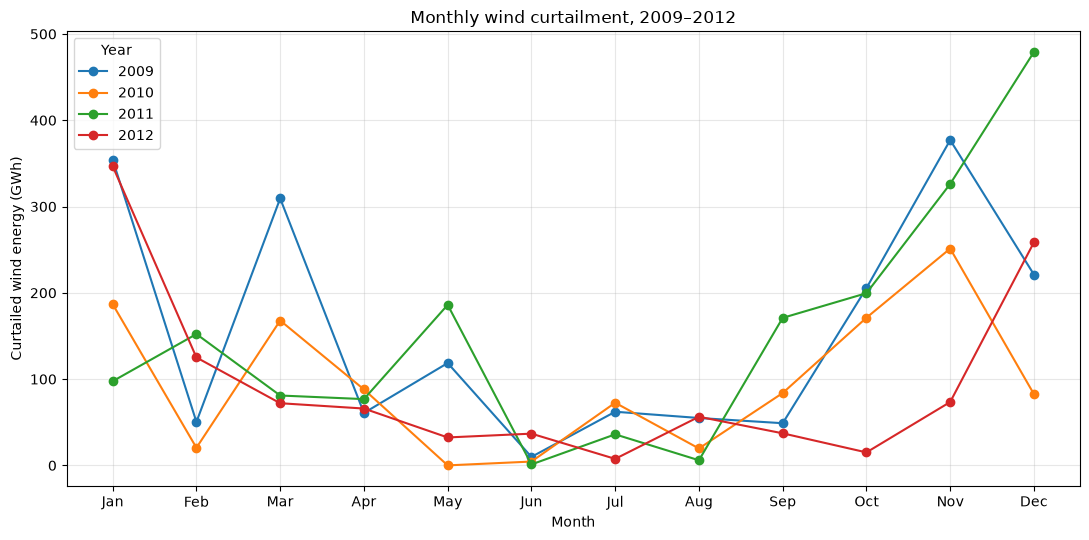

In [13]:
# Aggregate curtailed energy by year and month.
monthly_curtailment = (
    hourly.groupby(["year", "month"])["total_curtailment_mw"]
    .sum()
    .reset_index()
)

# Convert MWh to GWh for a more readable figure.
monthly_curtailment["curtailed_energy_gwh"] = (
    monthly_curtailment["total_curtailment_mw"] / 1000
)

# Define month labels for the horizontal axis.
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Create the figure.
fig, ax = plt.subplots(figsize=(11, 5.5))

# Plot one monthly profile for each year.
for year in years:

    # Select the observations belonging to the current year.
    year_data = monthly_curtailment[
        monthly_curtailment["year"] == year
    ]

    # Plot monthly curtailed energy.
    ax.plot(
        year_data["month"],
        year_data["curtailed_energy_gwh"],
        marker="o",
        label=str(year)
    )

# Configure the horizontal axis.
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)

# Add labels and title.
ax.set_xlabel("Month")
ax.set_ylabel("Curtailed wind energy (GWh)")
ax.set_title("Monthly wind curtailment, 2009–2012")

# Add legend and grid.
ax.legend(title="Year")
ax.grid(alpha=0.3)

# Save and display the figure.
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "monthly_curtailment_by_year.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 5.2 Daily cycle of wind curtailment

The daily cycle analysis investigates whether wind curtailment is concentrated
at particular times of the day.

Two complementary quantities are considered:

1. Mean curtailed power for each hour of the day.
2. Probability of observing non-zero curtailment during each hour.

The first quantity describes the average magnitude of curtailment, while
the second describes how frequently the system experiences curtailment.

This distinction is relevant when considering flexible demand, since
the timing and persistence of curtailment may influence the usefulness
of demand-side interventions.

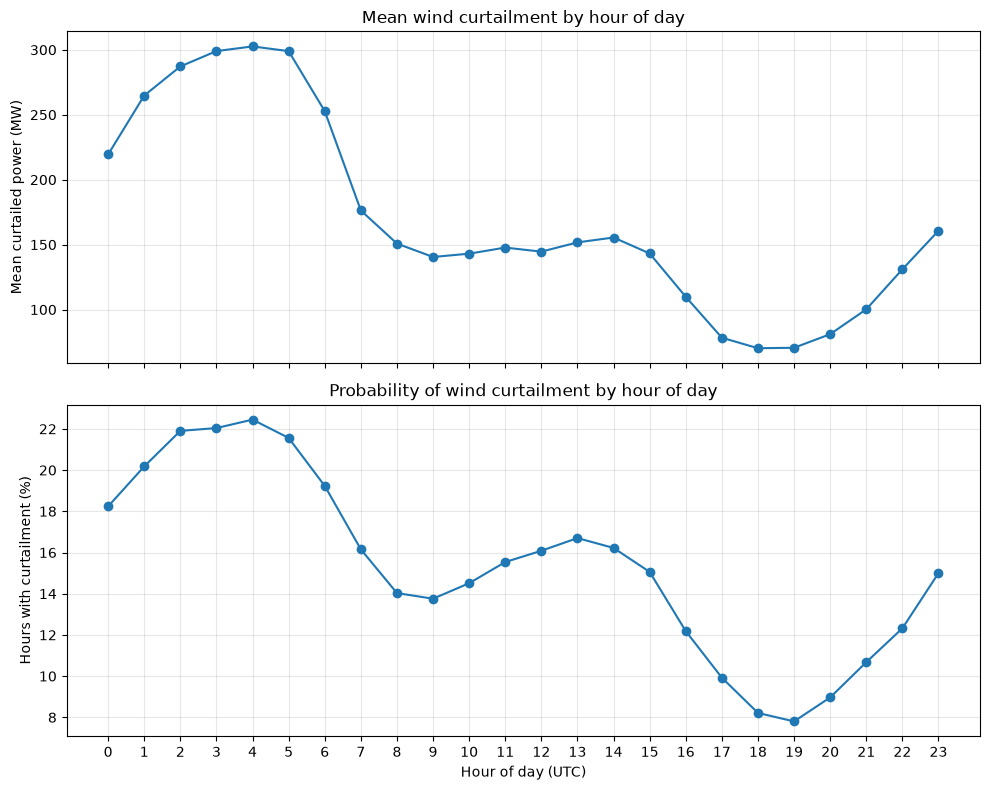

In [14]:
# Calculate the mean curtailed power for each hour of the day.
hourly_profile = (
    hourly.groupby("hour")["total_curtailment_mw"]
    .mean()
)

# Calculate the proportion of observations with curtailment for each hour.
curtailment_probability = (
    hourly.groupby("hour")["curtailment_occurs"]
    .mean() * 100
)

# Create two vertically arranged plots.
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Plot mean curtailed power.
axes[0].plot(
    hourly_profile.index,
    hourly_profile.values,
    marker="o"
)
axes[0].set_ylabel("Mean curtailed power (MW)")
axes[0].set_title("Mean wind curtailment by hour of day")
axes[0].grid(alpha=0.3)

# Plot the probability of curtailment.
axes[1].plot(
    curtailment_probability.index,
    curtailment_probability.values,
    marker="o"
)
axes[1].set_xlabel("Hour of day (UTC)")
axes[1].set_ylabel("Hours with curtailment (%)")
axes[1].set_title("Probability of wind curtailment by hour of day")
axes[1].set_xticks(range(0, 24))
axes[1].grid(alpha=0.3)

# Adjust spacing and save the figure.
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "daily_curtailment_profile.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()